## Predicción de Rentabilidad de Acciones

En este estudio de caso usaremos diversos modelos basados en aprendizaje supervisado para predecir
el precio de las acciones de Microsoft utilizando activos correlacionados y sus propios datos históricos.

## Contenido

* [1. Definición del Problema](#0)
* [2. Comenzando - Cargar Librerías y Conjunto de Datos](#1)
    * [2.1. Cargar Librerías](#1.1)    
    * [2.2. Cargar Conjunto de Datos](#1.2)
* [3. Análisis Exploratorio de Datos](#2)
    * [3.1 Estadísticos Descriptivos](#2.1)    
    * [3.2. Visualización de Datos](#2.2)
* [4. Preparación de Datos](#3)
    * [4.1 Limpieza de Datos](#3.1)    
    * [4.2. Selección de Características](#3.2) 
* [5. Evaluación de Algoritmos y Modelos](#4)        
    * [5.1. División Entrenamiento/Prueba](#4.1)
    * [5.2. Métricas de Evaluación](#4.2)
    * [5.3. Comparar Modelos y Algoritmos](#4.3)
        * [5.3.1 Modelos de Machine Learning - scikit-learn](#4.3.1)
* [6. Ajuste del Modelo y Búsqueda en Malla](#5)
* [7. Finalizar el modelo](#6)
    * [7.1. Resultado en el conjunto de prueba](#6.1)
    * [7.2. Guardar Modelo para Uso Posterior](#6.2)     

<a id='0'></a>
# 1. Definición del Problema

En el marco de regresión supervisada utilizado para este estudio de caso, el rendimiento semanal de las
acciones de Microsoft es la variable predicha. Necesitamos entender qué afecta el precio de las acciones de Microsoft e incorporar la mayor cantidad de información posible al modelo. 

Para este estudio de caso, además de los datos históricos de Microsoft, las variables independientes utilizadas son los siguientes activos potencialmente correlacionados:
* Acciones: IBM (IBM) y Alphabet (GOOGL)
* Divisas: USD/JPY y GBP/USD
* Índices: S&P 500, Dow Jones y VIX


<a id='1'></a>
# 2. Comenzando - Cargar los datos y paquetes de Python

<a id='1.1'></a>
## 2.1. Cargar los paquetes de Python

In [ ]:
!pip install yfinance

In [36]:
# Cargar librerías
import numpy as np
import pandas as pd
import yfinance as yf
from matplotlib import pyplot
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
#from sklearn.tree import DecisionTreeRegressor
#from sklearn.neighbors import KNeighborsRegressor
#from sklearn.svm import SVR
#from sklearn.ensemble import RandomForestRegressor
#from sklearn.ensemble import GradientBoostingRegressor
#from sklearn.ensemble import ExtraTreesRegressor
#from sklearn.ensemble import AdaBoostRegressor
#from sklearn.neural_network import MLPRegressor

# Librerías para Modelos de Aprendizaje Profundo
#from keras.models import Sequential
#from keras.layers import Dense
#from keras.optimizers import SGD
#from keras.layers import LSTM
#from keras.wrappers.scikit_learn import KerasRegressor

# Librerías para Modelos Estadísticos
import statsmodels.api as sm

# Librerías para Guardar el Modelo
from pickle import dump
from pickle import load

# Modelos de Series Temporales
from statsmodels.tsa.arima_model import ARIMA
#from statsmodels.tsa.statespace.sarimax import SARIMAX

# Métricas de Error
from sklearn.metrics import mean_squared_error

# Selección de Características
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2, f_regression


# Gráficos
from pandas.plotting import scatter_matrix
from statsmodels.graphics.tsaplots import plot_acf


In [34]:
# Deshabilitar las advertencias
import warnings
warnings.filterwarnings('ignore')

<a id='1.2'></a>
## 2.2. Cargar los Datos

A continuación, extraemos los datos requeridos para nuestro análisis utilizando Yahoo Finance (yfinance). 

In [37]:
# Tickers para acciones
stk_tickers = ['MSFT', 'IBM', 'GOOGL']
# Tickers Yahoo Finance: divisas (USD/JPY, GBP/USD) e índices (S&P 500, Dow Jones, VIX)
ccy_tickers_yf = ['JPY=X', 'GBP=X']
idx_tickers_yf = ['^GSPC', '^DJI', '^VIX']

# Descargar desde Yahoo Finance. period='5y' es necesario: X4 requiere 60 días de historia (MSFT_12DT). Sin ello yfinance trae solo ~1 mes y el dataset queda vacío.
stk_data = yf.download(stk_tickers, period='5y', auto_adjust=False, progress=False, threads=False, ignore_tz=True)

# Divisas e índices: extraer Adj Close y renombrar columnas para mantener compatibilidad
ccy_data = yf.download(ccy_tickers_yf, period='5y', auto_adjust=False, progress=False, threads=False, ignore_tz=True)
ccy_data = ccy_data['Adj Close'].copy()
ccy_data.columns = ['DEXJPUS', 'DEXUSUK']

idx_data = yf.download(idx_tickers_yf, period='5y', auto_adjust=False, progress=False, threads=False, ignore_tz=True)
idx_data = idx_data['Adj Close'].copy()
idx_data.columns = ['SP500', 'DJIA', 'VIXCLS']

In [38]:
idx_data

,SP500,DJIA,VIXCLS
Date,,,
2021-02-26,30932.369,3811.15,27.95
2021-03-01,31535.510,3901.82,23.35
2021-03-02,31391.520,3870.29,24.10
2021-03-03,31270.090,3819.72,26.67
2021-03-04,30924.141,3768.47,28.57
...,...,...,...
2026-02-20,49625.969,6909.51,19.09
2026-02-23,48804.059,6837.75,21.01
2026-02-24,49174.500,6890.07,19.55


A continuación, necesitamos una serie a predecir. Elegimos predecir usando rendimientos semanales. Aproximamos esto utilizando rendimientos de períodos de 5 días hábiles.

In [39]:
return_period = 5

Ahora definimos nuestra serie Y y nuestra serie X

Y: Rendimientos **futuros** de MSFT

X:

    a. Rendimientos GOOGL a 5 días hábiles
    b. Rendimientos IBM a 5 días hábiles    
    c. Rendimientos USD/JPY a 5 días hábiles    
    d. Rendimientos GBP/USD a 5 días hábiles    
    e. Rendimientos S&P 500 a 5 días hábiles    
    f. Rendimientos Dow Jones a 5 días hábiles    
    g. Rendimientos MSFT a 5 días hábiles    
    h. Rendimientos MSFT a 15 días hábiles    
    i. Rendimientos MSFT a 30 días hábiles    
    j. Rendimientos MSFT a 60 días hábiles

Eliminamos los rendimientos pasados de MSFT cuando usamos los modelos de series temporales.

In [40]:
Y = np.log(stk_data.loc[:, ('Adj Close', 'MSFT')]).diff(return_period).shift(-return_period)
Y.name = Y.name[-1]+'_pred'

X1 = np.log(stk_data.loc[:, [('Adj Close', 'GOOGL'), ('Adj Close', 'IBM')]]).diff(return_period)
X1.columns = X1.columns.droplevel()
X2 = np.log(ccy_data).diff(return_period)
X3 = np.log(idx_data).diff(return_period)

X4 = pd.concat([np.log(stk_data.loc[:, ('Adj Close', 'MSFT')]).diff(i) for i in [return_period, return_period*3, return_period*6, return_period*12]], axis=1).dropna()
X4.columns = ['MSFT_DT', 'MSFT_3DT', 'MSFT_6DT', 'MSFT_12DT']

X = pd.concat([X1, X2, X3, X4], axis=1)

dataset = pd.concat([Y, X], axis=1).dropna().iloc[::return_period, :]
Y = dataset.loc[:, Y.name]
X = dataset.loc[:, X.columns]

In [41]:
dataset

,MSFT_pred,GOOGL,IBM,DEXJPUS,DEXUSUK,SP500,DJIA,VIXCLS,MSFT_DT,MSFT_3DT,MSFT_6DT,MSFT_12DT
Date,,,,,,,,,,,,
2021-05-24,-0.014,0.031,-0.003,-0.003,-4.516e-03,1.926e-03,8.076e-03,-0.069,0.025,-0.002,-0.018,0.079
2021-06-01,0.021,0.008,-0.004,-0.005,5.881e-03,5.258e-03,1.188e-03,-0.028,-0.014,0.003,-0.043,0.068
2021-06-08,0.023,0.007,0.033,0.004,-2.002e-03,7.087e-04,5.984e-03,-0.047,0.021,0.032,-0.033,0.071
2021-06-15,0.027,0.012,0.002,0.005,6.995e-03,-8.723e-03,4.562e-03,-0.003,0.023,0.030,0.028,0.117
2021-06-22,0.022,0.007,-0.020,0.013,3.022e-03,-1.037e-02,-3.530e-05,-0.021,0.027,0.071,0.074,0.118
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-01-14,-0.018,0.042,0.041,0.005,1.582e-02,3.129e-03,8.189e-04,0.085,-0.051,-0.054,-0.058,-0.110
2026-01-22,-0.040,-0.016,-0.048,0.002,3.409e-04,4.757e-03,-1.915e-03,-0.069,-0.018,-0.077,-0.085,-0.147
2026-01-29,-0.096,0.023,0.048,-0.030,-3.441e-02,-6.347e-03,8.019e-03,0.076,-0.040,-0.109,-0.091,-0.176


In [42]:
X

,GOOGL,IBM,DEXJPUS,DEXUSUK,SP500,DJIA,VIXCLS,MSFT_DT,MSFT_3DT,MSFT_6DT,MSFT_12DT
Date,,,,,,,,,,,
2021-05-24,0.031,-0.003,-0.003,-4.516e-03,1.926e-03,8.076e-03,-0.069,0.025,-0.002,-0.018,0.079
2021-06-01,0.008,-0.004,-0.005,5.881e-03,5.258e-03,1.188e-03,-0.028,-0.014,0.003,-0.043,0.068
2021-06-08,0.007,0.033,0.004,-2.002e-03,7.087e-04,5.984e-03,-0.047,0.021,0.032,-0.033,0.071
2021-06-15,0.012,0.002,0.005,6.995e-03,-8.723e-03,4.562e-03,-0.003,0.023,0.030,0.028,0.117
2021-06-22,0.007,-0.020,0.013,3.022e-03,-1.037e-02,-3.530e-05,-0.021,0.027,0.071,0.074,0.118
...,...,...,...,...,...,...,...,...,...,...,...
2026-01-14,0.042,0.041,0.005,1.582e-02,3.129e-03,8.189e-04,0.085,-0.051,-0.054,-0.058,-0.110
2026-01-22,-0.016,-0.048,0.002,3.409e-04,4.757e-03,-1.915e-03,-0.069,-0.018,-0.077,-0.085,-0.147
2026-01-29,0.023,0.048,-0.030,-3.441e-02,-6.347e-03,8.019e-03,0.076,-0.040,-0.109,-0.091,-0.176


In [43]:
Y

Date
2021-05-24   -0.014
2021-06-01    0.021
2021-06-08    0.023
2021-06-15    0.027
2021-06-22    0.022
              ...  
2026-01-14   -0.018
2026-01-22   -0.040
2026-01-29   -0.096
2026-02-05    0.021
2026-02-12   -0.009
Name: MSFT_pred, Length: 238, dtype: float64

<a id='2'></a>
# 3. Análisis Exploratorio de Datos

<a id='2.1'></a>
## 3.1. Estadísticos Descriptivos

Echemos un vistazo al conjunto de datos que tenemos

In [44]:
pd.set_option('display.precision', 3)
dataset.describe()

,MSFT_pred,GOOGL,IBM,DEXJPUS,DEXUSUK,SP500,DJIA,VIXCLS,MSFT_DT,MSFT_3DT,MSFT_6DT,MSFT_12DT
count,238.000,238.000,238.000,2.380e+02,238.000,238.000,238.000,2.380e+02,238.000,238.000,238.000,238.000
mean,0.002,0.004,0.003,1.521e-04,0.001,0.002,0.002,-3.248e-04,0.002,0.007,0.015,0.034
std,0.035,0.041,0.034,1.288e-02,0.014,0.019,0.022,1.495e-01,0.035,0.060,0.081,0.114
min,-0.099,-0.128,-0.127,-6.529e-02,-0.054,-0.055,-0.060,-4.953e-01,-0.099,-0.154,-0.208,-0.263
25%,-0.022,-0.021,-0.016,-6.577e-03,-0.006,-0.011,-0.009,-7.329e-02,-0.022,-0.031,-0.039,-0.048
50%,0.007,0.005,0.003,-1.382e-05,0.002,0.004,0.004,-9.040e-03,0.007,0.010,0.016,0.035
75%,0.024,0.028,0.024,6.359e-03,0.010,0.012,0.016,7.033e-02,0.024,0.044,0.072,0.121
max,0.109,0.124,0.141,5.909e-02,0.039,0.052,0.069,5.485e-01,0.109,0.224,0.256,0.356


In [45]:
dataset.head()

,MSFT_pred,GOOGL,IBM,DEXJPUS,DEXUSUK,SP500,DJIA,VIXCLS,MSFT_DT,MSFT_3DT,MSFT_6DT,MSFT_12DT
Date,,,,,,,,,,,,
2021-05-24,-0.014,0.031,-0.003,-0.003,-0.005,1.926e-03,8.076e-03,-0.069,0.025,-0.002,-0.018,0.079
2021-06-01,0.021,0.008,-0.004,-0.005,0.006,5.258e-03,1.188e-03,-0.028,-0.014,0.003,-0.043,0.068
2021-06-08,0.023,0.007,0.033,0.004,-0.002,7.087e-04,5.984e-03,-0.047,0.021,0.032,-0.033,0.071
2021-06-15,0.027,0.012,0.002,0.005,0.007,-8.723e-03,4.562e-03,-0.003,0.023,0.030,0.028,0.117
2021-06-22,0.022,0.007,-0.020,0.013,0.003,-1.037e-02,-3.530e-05,-0.021,0.027,0.071,0.074,0.118


<a id='2.2'></a>
## 3.2. Visualización de Datos

A continuación, veamos la distribución de los datos en todo el período

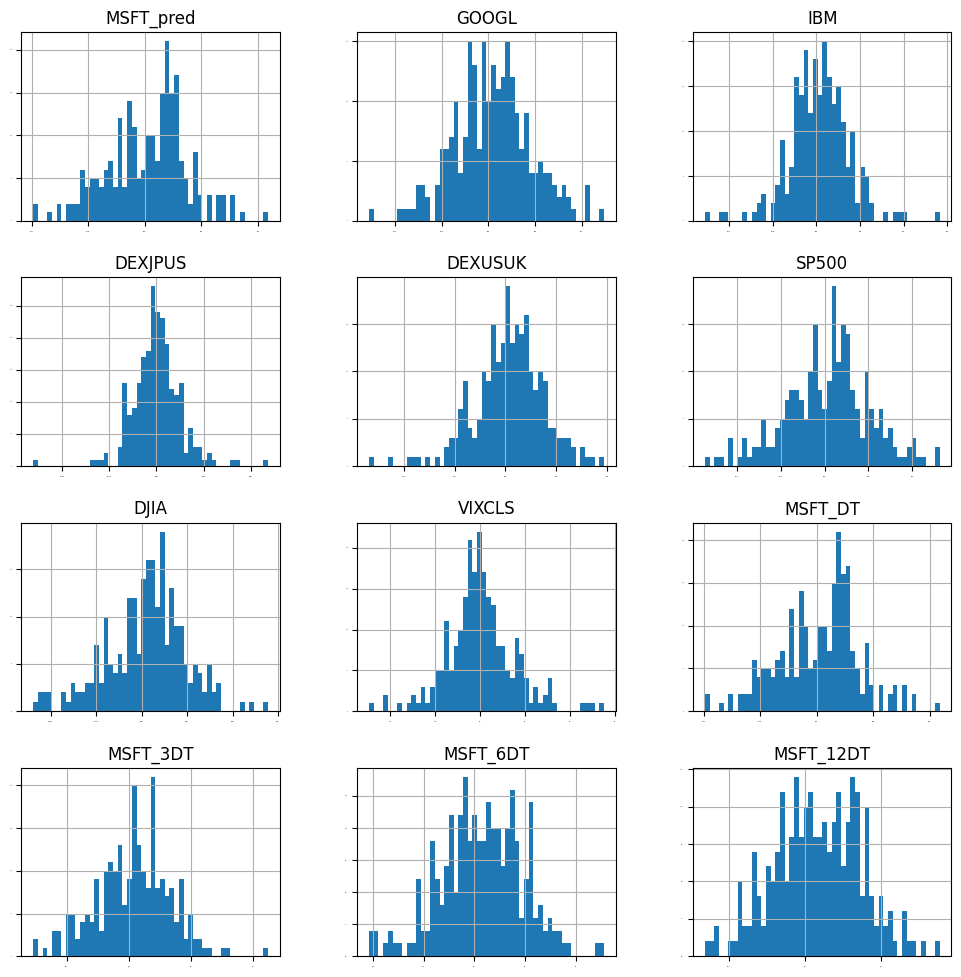

In [46]:
dataset.hist(bins=50, sharex=False, sharey=False, xlabelsize=1, ylabelsize=1, figsize=(12,12))
pyplot.show()

El histograma anterior muestra la distribución de cada serie de forma individual. A continuación, veamos la distribución de densidad en la misma escala del eje x.

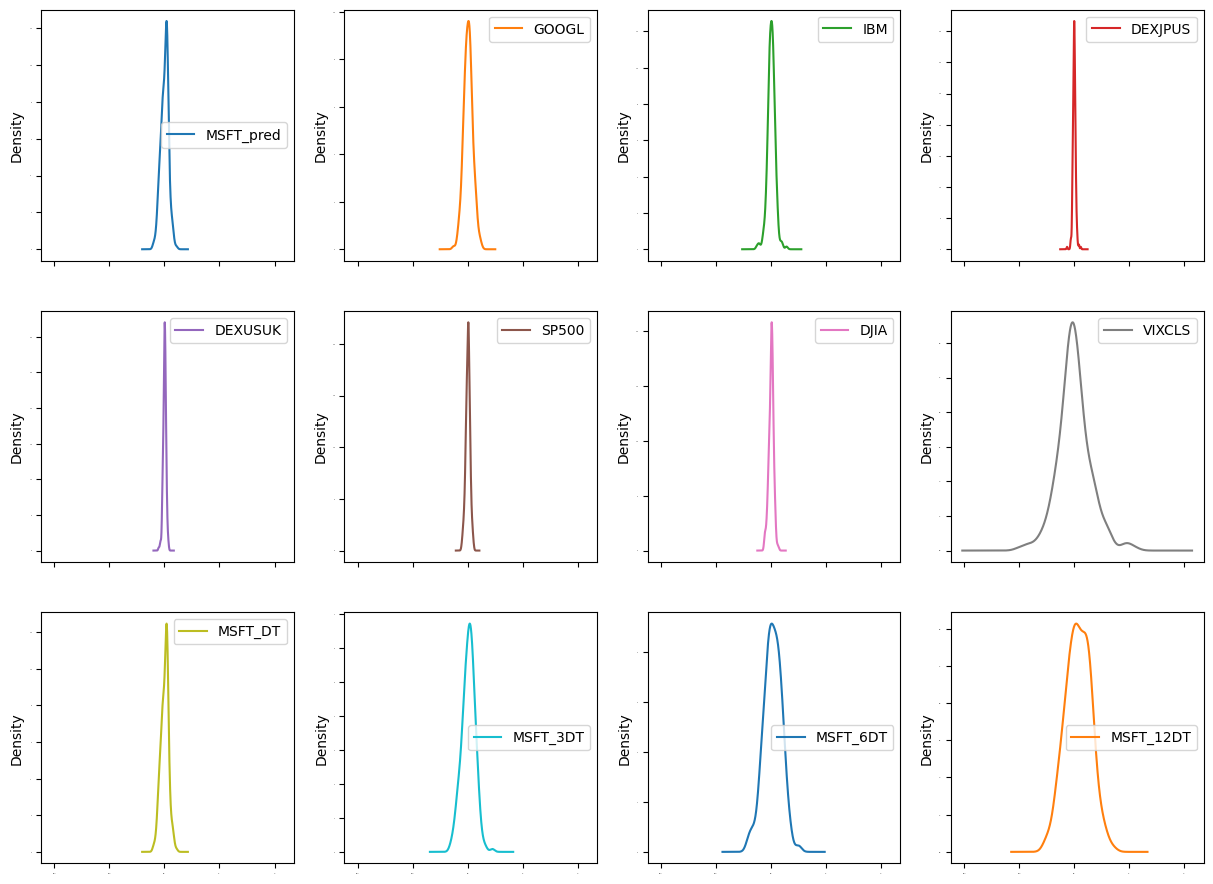

In [47]:
dataset.plot(kind='density', subplots=True, layout=(4,4), sharex=True, legend=True, fontsize=1, figsize=(15,15))
pyplot.show()

Podemos ver que el VIX tiene una varianza mucho mayor en comparación con las otras distribuciones.

Para tener una idea de la interdependencia de los datos, observamos el gráfico de dispersión y la matriz de correlación

<Axes: title={'center': 'Correlation Matrix'}>

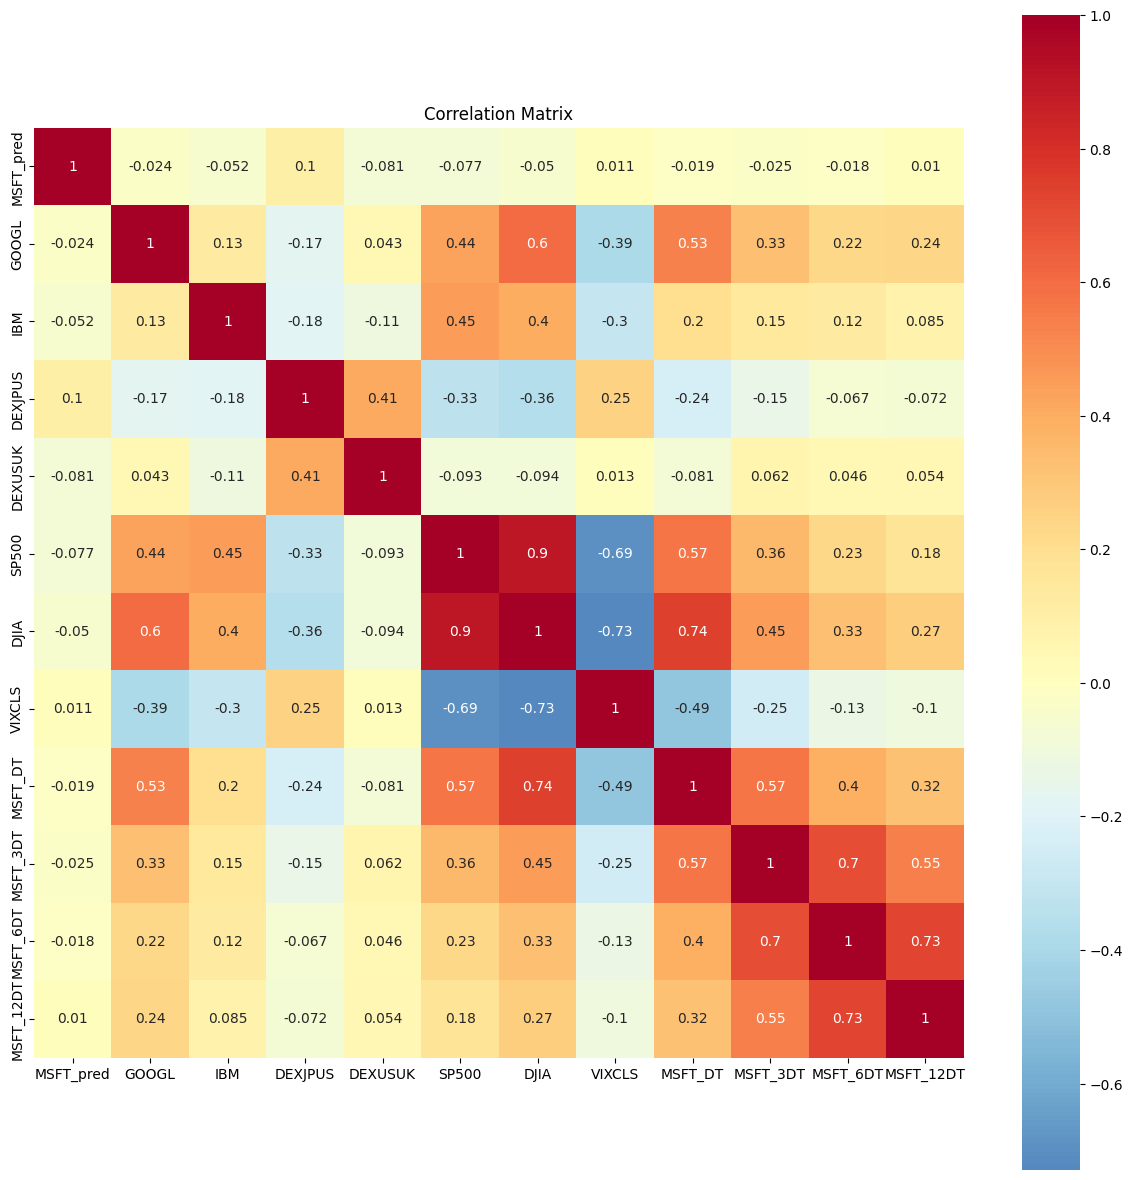

In [48]:
correlation = dataset.corr()
pyplot.figure(figsize=(15,15))
pyplot.title('Correlation Matrix')
sns.heatmap(correlation, vmax=1, square=True, annot=True, cmap='RdYlBu_r', center=0)

Mirando el gráfico de correlación anterior, vemos cierta correlación de la variable predicha
con los rendimientos rezagados de MSFT a 5 días, 15 días, 30 días y 60 días. 

<Figure size 1500x1500 with 0 Axes>

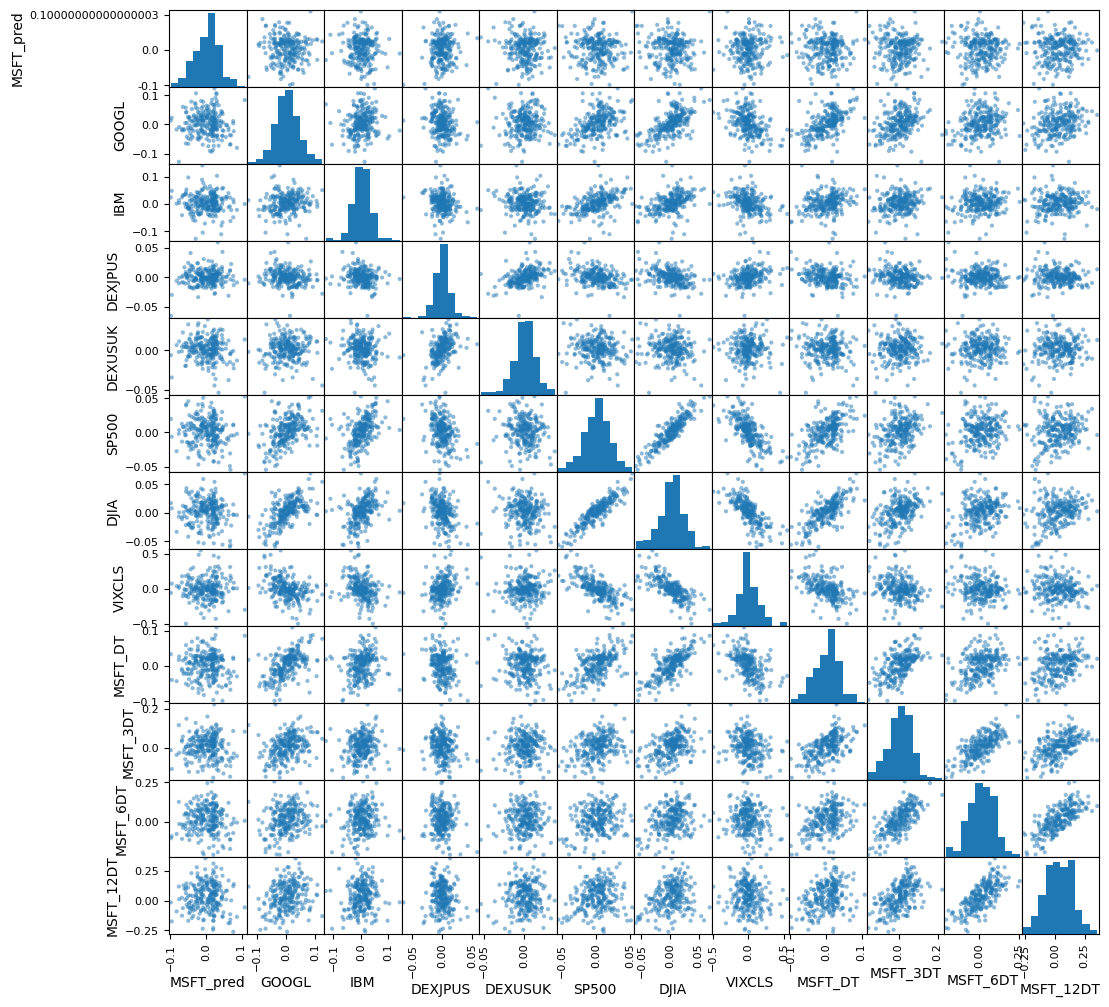

In [49]:
pyplot.figure(figsize=(15,15))
scatter_matrix(dataset,figsize=(12,12))
pyplot.show()

Mirando el gráfico de dispersión anterior, vemos una relación lineal de la variable predicha
con los rendimientos rezagados de MSFT a 15 días, 30 días y 60 días.

Podemos ver que para MSFT ha habido una tendencia general al alza. Esto debería reflejarse en los términos constante/sesgo de nuestros modelos

<a id='3'></a>
## 4. Preparación de Datos

<a id='3.2'></a>
## 4.2. Selección de Características

Usamos la función **SelectKBest** de sklearn para tener una idea de la importancia de las características.

**¿Qué hace SelectKBest?** Selecciona las *k* características más relevantes según una función de puntuación estadística. En problemas de regresión, usa `f_regression`, que mide la correlación lineal (test F) entre cada característica y la variable objetivo: a mayor puntuación, más poder predictivo. Así podemos identificar qué variables (GOOGL, IBM, divisas, índices, etc.) aportan más información para predecir los rendimientos de MSFT.

**neg_mean_squared_error** = −MSE, donde MSE (Mean Squared Error) se calcula como:

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

con $y_i$ = valor real, $\hat{y}_i$ = predicción, $n$ = número de observaciones. Scikit-learn usa el signo negativo para que en cross-validation "mayor puntuación = mejor modelo".

In [50]:
bestfeatures = SelectKBest(k=5, score_func=f_regression)
fit = bestfeatures.fit(X,Y)
dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(X.columns)
#concat two dataframes for better visualization 
featureScores = pd.concat([dfcolumns,dfscores],axis=1)
featureScores.columns = ['Specs','Score']  #naming the dataframe columns
featureScores.nlargest(10,'Score').set_index('Specs')  #print 10 best features

,Score
Specs,
DEXJPUS,2.472
DEXUSUK,1.546
SP500,1.407
IBM,0.649
DJIA,0.594
MSFT_3DT,0.153
GOOGL,0.135
MSFT_DT,0.088
MSFT_6DT,0.073


Vemos que DEXJPUS parece ser la característica más importante y el VIXCLS la menos importante.

<a id='4'></a>
# 5. Evaluación de Algoritmos y Modelos

<a id='4.1'></a>
## 5.1. División Entrenamiento/Prueba y Métricas de Evaluación

A continuación, comenzamos dividiendo nuestros datos en conjuntos de entrenamiento y prueba. Si vamos a usar modelos de series temporales, debemos dividir los datos en series continuas.

In [51]:
validation_size = 0.2

# Si los datos no dependen de la serie temporal, dividir entrenamiento y prueba aleatoriamente
# seed = 7
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=validation_size, random_state=seed)

# Si los datos no dependen de la serie temporal, la división debe hacerse basada en muestra secuencial
#This can be done by selecting an arbitrary split point in the ordered list of observations and creating two new datasets.
train_size = int(len(X) * (1-validation_size))
X_train, X_test = X[0:train_size], X[train_size:len(X)]
Y_train, Y_test = Y[0:train_size], Y[train_size:len(X)]

<a id='4.2'></a>
## 5.2. Opciones de Prueba y Métricas de Evaluación

In [52]:
num_folds = 10
seed = 7
# neg_mean_squared_error = -MSE
# MSE (Mean Squared Error):  MSE = (1/n) · Σ(y_i - ŷ_i)²
# scikit-learn devuelve -MSE en cross_val_score (mayor = mejor). Por eso multiplicamos por -1 para obtener MSE positivo.
scoring = 'neg_mean_squared_error' 

**neg_mean_squared_error** = MSE, donde MSE (Mean Squared Error) se calcula como:

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

con $y_i$ = valor real, $\hat{y}_i$ = predicción, $n$ = número de observaciones. Scikit-learn usa el signo negativo para que en cross-validation "mayor puntuación = mejor modelo".

<a id='4.3'></a>
## 5.3. Comparar Modelos y Algoritmos

<a id='4.3.1'></a>
### 5.3.1 Modelos de Machine Learning - scikit-learn

##### Algoritmos de Regresión

#### 5.3.1a Definición de modelos

In [53]:
models = []
models.append(('LR', LinearRegression()))
models.append(('LASSO', Lasso()))
models.append(('EN', ElasticNet()))

Antes de la validación cruzada, analizamos cada modelo: **coeficientes** (valor y signo), **p-valores** (LR), **R²**, y **supuestos** (normalidad, homocedasticidad, independencia) con gráficos.

 MODELO: LR

1. COEFICIENTES:


,Variable,Coeficiente,Signo
0,Intercepto,0.003,+
1,GOOGL,0.008,+
2,IBM,-0.035,-
3,DEXJPUS,0.432,+
4,DEXUSUK,-0.455,-
5,SP500,-0.239,-
6,DJIA,0.081,+
7,VIXCLS,-0.003,-
8,MSFT_DT,0.063,+
9,MSFT_3DT,-0.044,-



2. R² (entrenamiento):


,Métrica,Valor
0,R²,0.06



3. COEFICIENTES, p-VALORES Y SIGNIFICANCIA (OLS):


,Coef.,t,p-valor,Significativo (α=0.05)
const,0.003,1.194,0.234,No
GOOGL,0.008,0.089,0.929,No
IBM,-0.035,-0.382,0.703,No
DEXJPUS,0.432,1.941,0.054,No
DEXUSUK,-0.455,-2.166,0.032,Sí ***
SP500,-0.239,-0.676,0.500,No
DJIA,0.081,0.197,0.844,No
VIXCLS,-0.003,-0.117,0.907,No
MSFT_DT,0.063,0.475,0.635,No
MSFT_3DT,-0.044,-0.659,0.511,No



4. SUPUESTOS DE REGRESIÓN:


,Supuesto,p-valor/Estadístico,Criterio,¿Se cumple?
0,Normalidad (Shapiro-Wilk),0.0899,p > 0.05,✓
1,Homocedasticidad (Breusch-Pagan),0.1509,p > 0.05,✓
2,Independencia (Durbin-Watson),1.9591,1.5 ≤ DW ≤ 2.5,✓


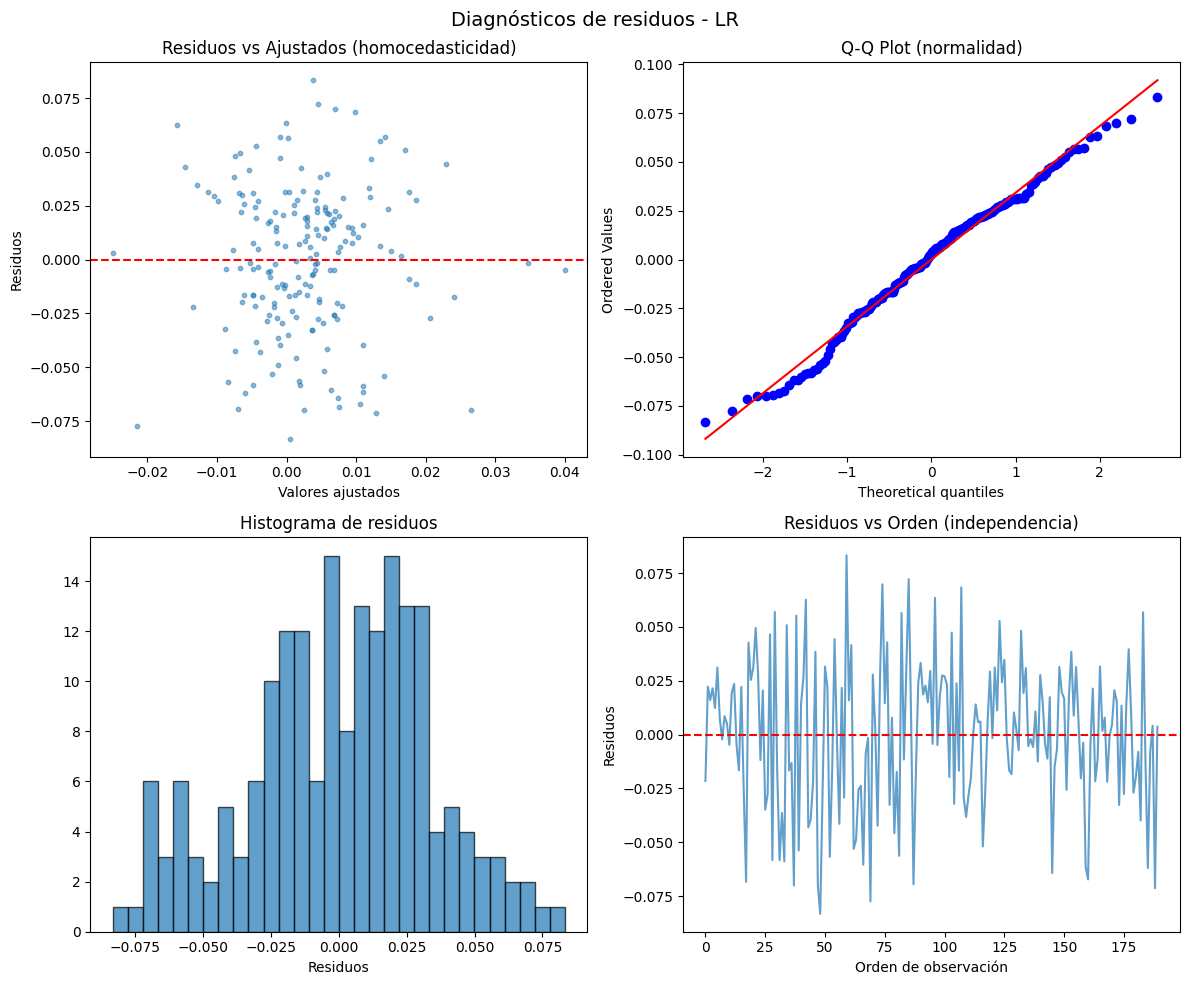



 MODELO: LASSO

1. COEFICIENTES:


,Variable,Coeficiente,Signo
0,Intercepto,0.003,+
1,GOOGL,0.000,-
2,IBM,0.000,-
3,DEXJPUS,0.000,-
4,DEXUSUK,0.000,-
5,SP500,0.000,-
6,DJIA,0.000,-
7,VIXCLS,0.000,-
8,MSFT_DT,0.000,-
9,MSFT_3DT,0.000,-



2. R² (entrenamiento):


,Métrica,Valor
0,R²,0.0



4. SUPUESTOS DE REGRESIÓN:


,Supuesto,p-valor/Estadístico,Criterio,¿Se cumple?
0,Normalidad (Shapiro-Wilk),0.1226,p > 0.05,✓
1,Homocedasticidad (Breusch-Pagan),0.0083,p > 0.05,✗
2,Independencia (Durbin-Watson),2.0762,1.5 ≤ DW ≤ 2.5,✓


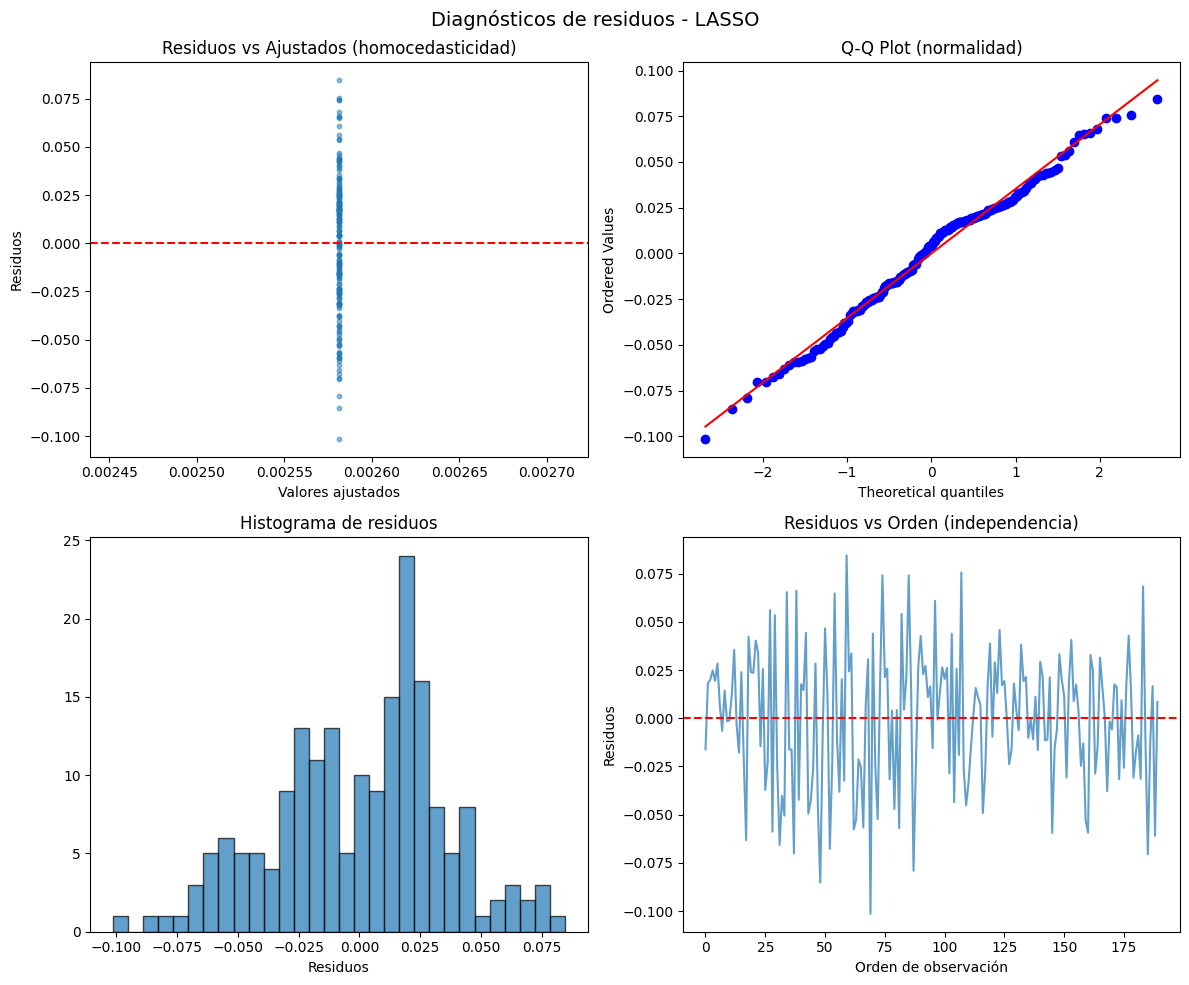



 MODELO: EN

1. COEFICIENTES:


,Variable,Coeficiente,Signo
0,Intercepto,0.003,+
1,GOOGL,0.000,-
2,IBM,0.000,-
3,DEXJPUS,0.000,-
4,DEXUSUK,0.000,-
5,SP500,0.000,-
6,DJIA,0.000,-
7,VIXCLS,0.000,-
8,MSFT_DT,0.000,-
9,MSFT_3DT,0.000,-



2. R² (entrenamiento):


,Métrica,Valor
0,R²,0.0



4. SUPUESTOS DE REGRESIÓN:


,Supuesto,p-valor/Estadístico,Criterio,¿Se cumple?
0,Normalidad (Shapiro-Wilk),0.1226,p > 0.05,✓
1,Homocedasticidad (Breusch-Pagan),0.0083,p > 0.05,✗
2,Independencia (Durbin-Watson),2.0762,1.5 ≤ DW ≤ 2.5,✓


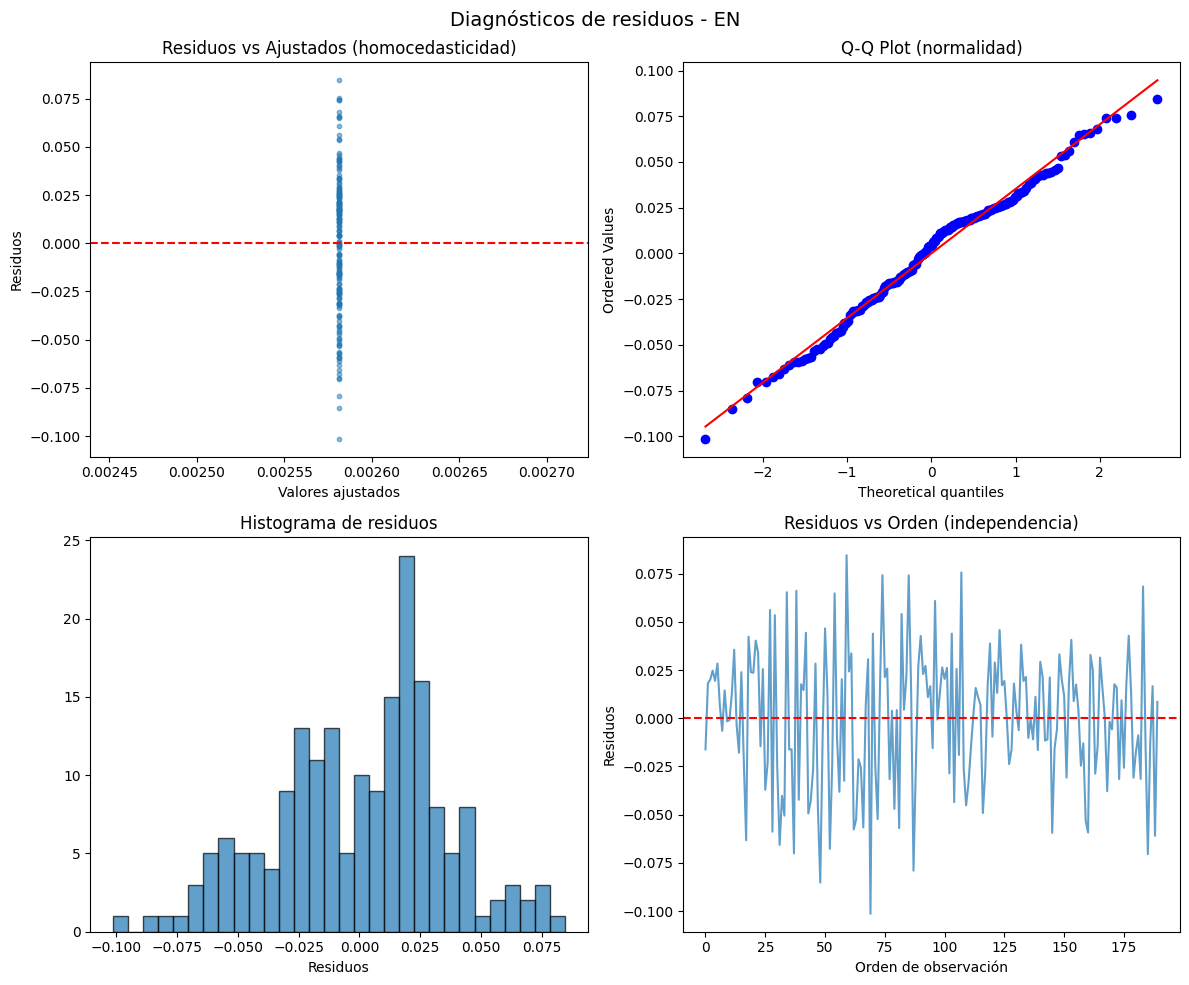

In [54]:
from sklearn.metrics import r2_score
from scipy import stats as scipy_stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from IPython.display import display

for name, model in models:
    print("=" * 70)
    print(f" MODELO: {name}")
    print("=" * 70)
    
    # Ajustar modelo
    model.fit(X_train, Y_train)
    y_pred = model.predict(X_train)
    residuos = Y_train.values - y_pred
    
    # --- Coeficientes (valor y signo) ---
    if hasattr(model, 'coef_'):
        coef_df = pd.DataFrame({
            'Variable': X_train.columns.tolist(),
            'Coeficiente': model.coef_,
            'Signo': ['+' if c > 0 else '-' for c in model.coef_]
        })
        if hasattr(model, 'intercept_') and model.intercept_ is not None:
            coef_df = pd.concat([pd.DataFrame({'Variable': ['Intercepto'], 'Coeficiente': [model.intercept_], 'Signo': ['+' if model.intercept_ > 0 else '-']}), coef_df], ignore_index=True)
        print("\n1. COEFICIENTES:")
        display(coef_df)
    
    # --- R² ---
    r2 = r2_score(Y_train, y_pred)
    df_r2 = pd.DataFrame({'Métrica': ['R²'], 'Valor': [r2]})
    print("\n2. R² (entrenamiento):")
    display(df_r2)
    
    # --- p-valores y significancia (solo para LR con statsmodels) ---
    if name == 'LR':
        model_ols = sm.OLS(Y_train, sm.add_constant(X_train)).fit()
        tab = model_ols.summary2().tables[1]
        pcol = 'P>|t|' if 'P>|t|' in tab.columns else next((c for c in tab.columns if 'P>' in str(c)), None)
        cols = ['Coef.', 'Std Err', 't'] + ([pcol] if pcol else [])
        df_ols = tab[[c for c in cols if c in tab.columns]].copy()
        df_ols = df_ols.rename(columns={pcol: 'p-valor'}) if pcol and pcol in df_ols.columns else df_ols
        if 'p-valor' in df_ols.columns:
            df_ols['Significativo (α=0.05)'] = df_ols['p-valor'].apply(lambda p: 'Sí ***' if p < 0.05 else 'No')
        print("\n3. COEFICIENTES, p-VALORES Y SIGNIFICANCIA (OLS):")
        display(df_ols)
    
    # --- Supuestos (DataFrame) ---
    if len(residuos) <= 5000:
        _, p_norm = scipy_stats.shapiro(residuos)
        test_norm = 'Shapiro-Wilk'
    else:
        _, p_norm = scipy_stats.kstest((residuos-residuos.mean())/residuos.std(), 'norm')
        test_norm = 'Kolmogorov-Smirnov'
    try:
        _, bp_pval, _, _ = het_breuschpagan(residuos, sm.add_constant(X_train).values)
    except: bp_pval = np.nan
    dw = durbin_watson(residuos)
    df_sup = pd.DataFrame({'Supuesto': ['Normalidad ('+test_norm+')', 'Homocedasticidad (Breusch-Pagan)', 'Independencia (Durbin-Watson)'], 'p-valor/Estadístico': [f'{p_norm:.4f}', f'{bp_pval:.4f}' if not np.isnan(bp_pval) else 'N/A', f'{dw:.4f}'], 'Criterio': ['p > 0.05', 'p > 0.05', '1.5 ≤ DW ≤ 2.5'], '¿Se cumple?': [('✓' if p_norm > 0.05 else '✗'), ('✓' if (not np.isnan(bp_pval) and bp_pval > 0.05) else '✗'), ('✓' if 1.5 <= dw <= 2.5 else '✗')]})
    print("\n4. SUPUESTOS DE REGRESIÓN:")
    display(df_sup)
    
    # --- Gráficos ---
    fig, axes = pyplot.subplots(2, 2, figsize=(12, 10))
    fig.suptitle(f'Diagnósticos de residuos - {name}', fontsize=14)
    
    axes[0,0].scatter(y_pred, residuos, alpha=0.5, s=10)
    axes[0,0].axhline(0, color='red', linestyle='--')
    axes[0,0].set_xlabel('Valores ajustados')
    axes[0,0].set_ylabel('Residuos')
    axes[0,0].set_title('Residuos vs Ajustados (homocedasticidad)')
    
    scipy_stats.probplot(residuos, dist="norm", plot=axes[0,1])
    axes[0,1].set_title('Q-Q Plot (normalidad)')
    
    axes[1,0].hist(residuos, bins=30, edgecolor='black', alpha=0.7)
    axes[1,0].set_xlabel('Residuos')
    axes[1,0].set_title('Histograma de residuos')
    
    axes[1,1].plot(range(len(residuos)), residuos, alpha=0.7)
    axes[1,1].axhline(0, color='red', linestyle='--')
    axes[1,1].set_xlabel('Orden de observación')
    axes[1,1].set_ylabel('Residuos')
    axes[1,1].set_title('Residuos vs Orden (independencia)')
    
    pyplot.tight_layout()
    pyplot.show()
    print("\n")

In [ ]:
# Modelos definidos en la celda anterior (ver sección 5.3.1a)

<a id='4.3.1'></a>
### 5.3.2 Validación Cruzada

Una vez seleccionados todos los modelos, iteramos sobre cada uno de ellos. Primero ejecutamos el análisis K-fold. Luego ejecutamos el modelo en todo el conjunto de datos de entrenamiento y prueba.

In [ ]:
names = []
kfold_results = []
test_results = []
train_results = []
for name, model in models:
    names.append(name)
    
    ## K Fold analysis:
    
    kfold = KFold(n_splits=num_folds, shuffle=True, random_state=seed)
    #converted mean square error to positive. The lower the beter
    cv_results = -1* cross_val_score(model, X_train, Y_train, cv=kfold, scoring=scoring)
    kfold_results.append(cv_results)
    

    # Full Training period
    res = model.fit(X_train, Y_train)
    train_result = mean_squared_error(res.predict(X_train), Y_train)
    train_results.append(train_result)
    
    # Test results
    test_result = mean_squared_error(res.predict(X_test), Y_test)
    test_results.append(test_result)
    
    msg = "%s: %f (%f) %f %f" % (name, cv_results.mean(), cv_results.std(), train_result, test_result)
    print(msg)

La comparación entre los modelos muestra que la **Regresión Lineal (LR)** presenta el menor error en entrenamiento (≈0.00116), pero el mayor error en prueba (≈0.00134), lo que sugiere una ligera presencia de sobreajuste, ya que el modelo se ajusta mejor a los datos de entrenamiento que a los datos no observados. En contraste, tanto **LASSO** como **Elastic Net (EN)** exhiben errores de entrenamiento ligeramente superiores (≈0.00123), pero errores de prueba menores y prácticamente iguales entre sí (≈0.00121), lo que indica una mejor capacidad de generalización. Este comportamiento evidencia el efecto positivo de la regularización (L1 en LASSO y combinación L1-L2 en Elastic Net), que introduce penalización sobre los coeficientes y reduce la varianza del modelo, mejorando su desempeño fuera de muestra. En consecuencia, aunque la regresión lineal tradicional minimiza mejor el error dentro de la muestra, los modelos regularizados resultan más adecuados cuando el objetivo principal es la predicción y la estabilidad del modelo ante nuevos datos.


#### Resultados K Fold

Comenzamos mirando los resultados de K Fold

In [ ]:
fig = pyplot.figure()
fig.suptitle('Algorithm Comparison: Kfold results')
ax = fig.add_subplot(111)
pyplot.boxplot(kfold_results)
ax.set_xticklabels(names)
fig.set_size_inches(15,8)
pyplot.show()

Vemos que la regresión lineal y la regresión regularizada, incluyendo la regresión Lasso (LASSO) y elastic net (EN), parecen funcionar bien.

#### Error de Entrenamiento y Prueba

In [ ]:
# compare algorithms
fig = pyplot.figure()

ind = np.arange(len(names))  # the x locations for the groups
width = 0.35  # the width of the bars

fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
pyplot.bar(ind - width/2, train_results,  width=width, label='Train Error')
pyplot.bar(ind + width/2, test_results, width=width, label='Test Error')
fig.set_size_inches(15,8)
pyplot.legend()
ax.set_xticks(ind)
ax.set_xticklabels(names)
pyplot.show()

La comparación entre los modelos muestra que la Regresión Lineal (LR) presenta el menor error en entrenamiento (≈0.00116), pero el mayor error en prueba (≈0.00134), lo que sugiere una ligera presencia de sobreajuste, ya que el modelo se ajusta mejor a los datos de entrenamiento que a los datos no observados. En contraste, tanto LASSO como Elastic Net (EN) exhiben errores de entrenamiento ligeramente superiores (≈0.00123), pero errores de prueba menores y prácticamente iguales entre sí (≈0.00121), lo que indica una mejor capacidad de generalización. Este comportamiento evidencia el efecto positivo de la regularización (L1 en LASSO y combinación L1-L2 en Elastic Net), que introduce penalización sobre los coeficientes y reduce la varianza del modelo, mejorando su desempeño fuera de muestra. En consecuencia, aunque la regresión lineal tradicional minimiza mejor el error dentro de la muestra, los modelos regularizados resultan más adecuados cuando el objetivo principal es la predicción y la estabilidad del modelo ante nuevos datos.

### Resumen

En síntesis, la regresión lineal y sus variantes regularizadas, como Lasso y Elastic Net, constituyen enfoques sólidos y prometedores para la predicción de precios de activos financieros. Estos modelos permiten capturar relaciones relevantes entre variables explicativas y precios, ofreciendo un marco flexible y estructurado para enfrentar problemas de sobreajuste y subajuste, que son desafíos recurrentes en la modelación financiera. Además, el desempeño predictivo puede mejorar significativamente mediante la incorporación de indicadores adicionales, como razones financieras (por ejemplo, P/E), volumen de negociación, indicadores técnicos o información proveniente de noticias. En conjunto, este enfoque configura un marco de modelado supervisado que facilita la estimación de riesgo y rentabilidad a partir de datos históricos, permitiendo evaluar estrategias y escenarios antes de comprometer capital real.